# 07 – Statistical tests
**Input:** `food_final.csv`, the final dataset for the model

Every test follows Hypotheses → Assumptions → Test → Result → Interpretation, with α = 0.05

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

pandas and numpy for the tables, scipy.stats for the tests, matplotlib for the plots

In [2]:
final = pd.read_csv('food_final.csv')
print(final.shape)

(126787, 53)


We read the final dataset: **126,787 rows and 53 columns**.

## Statistical tests
For the tests that compare before and after the change we use only Pre (before 1 July 2018) and Post (after 30 June 2019), and leave out the transition year, which is a mix of both, the transition year is tested separately in H4

**Note on independence:** chi-square and Mann–Whitney assume independent observations, the same business is inspected several times, so the inspections are not fully independent, we accept this as a limitation

In [3]:
pre_post = final[final['Period'].isin(['Pre', 'Post'])]
pre_post['Period'].value_counts()

Period
Pre     64293
Post    47780
Name: count, dtype: int64

Number of inspections used in the before/after tests: **64,293 Pre** and **47,780 Post**

**Effect size for chi-square tests**: With more than 100,000 rows almost every difference is significant, so we also report how big it is, Cramér's V = √(χ² / (n × (k − 1))) ( the formula for usual effect size for chi-square), where k is the smaller number of rows or columns of the table, it goes from 0 (no relationship) to 1 (perfect relationship) about 0.1 = small, 0.3 = medium, 0.5 = large 

In [4]:
def cramers_v(table):
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.values.sum()
    k = min(table.shape) - 1
    return np.sqrt(chi2 / (n * k))

A small function that calculates Cramér's V from a crosstab, so we can use it for every chi-square test

### H1a – Did the distribution of results change?
**H0:** the shares of Pass / Pass w/ Conditions / Fail are the same before and after the change
**H1:** the shares are different  
**Assumptions:** two categorical variables (Period, Results), independent inspections, every expected count ≥ 5
**Test:** chi-square test of independence

In [5]:
table_h1a = pd.crosstab(pre_post['Period'], pre_post['Results'])
table_h1a

Results,Fail,Pass,Pass w/ Conditions
Period,,,
Post,11343,23308,13129
Pre,13905,42441,7947


The counts of each result before and after

In [6]:
pd.crosstab(pre_post['Period'], pre_post['Results'], normalize='index').round(3)

Results,Fail,Pass,Pass w/ Conditions
Period,,,
Post,0.237,0.488,0.275
Pre,0.216,0.660,0.124


The same as shares (each row adds up to 1), from Pre to Post, Pass drops from 66.0% to 48.8%, Pass w/ Conditions more than doubles from 12.4% to 27.5%, and Fail rises only a little, from 21.6% to 23.7%

In [7]:
chi2, p, dof, expected = stats.chi2_contingency(table_h1a)
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p:.3e}, min expected = {expected.min():.0f}')
print(f"Cramer's V = {cramers_v(table_h1a):.3f}")

Chi-square = 4772.35, df = 2, p-value = 0.000e+00, min expected = 8985
Cramer's V = 0.206


Result and interpretation: χ^2 = 4,772.35, df = 2, p < 0.001 (smallest expected count 8,985, so the assumption holds), we **reject H0**: the distribution of results is different after the change, Cramér's V = **0.206**, a small-to-medium effect, most of the change is between Pass and Pass w/ Conditions, not in the fail rate

### H1b – Did the number of violations change?
**H0:** the number of violations per inspection has the same distribution before and after
**H1:** the distributions are different 
**Assumptions:** two independent groups, a numeric variable, the counts are not normal (right-skewed, many zeros, see the skewness and histograms in `06_Merge.ipynb`, quality check 6), so we use the non-parametric Mann–Whitney U test

In [8]:
pre_post.groupby('Period')[['Num_Violations', 'Num_Critical', 'Num_Serious']].median()

,Num_Violations,Num_Critical,Num_Serious
Period,,,
Post,3.0,0.0,0.0
Pre,3.0,0.0,0.0


Median number of violations before and after: 3 in both periods, the median of critical and serious violations is 0 in both periods

In [9]:
pre_post.groupby('Period')[['Num_Violations', 'Num_Critical', 'Num_Serious']].mean().round(2)

,Num_Violations,Num_Critical,Num_Serious
Period,,,
Post,4.25,0.20,0.91
Pre,3.45,0.24,0.36


Mean number of violations before and after: 3.45 (Pre) → 4.25 (Post), Critical violations go down a little (0.24 → 0.20), serious violations go up a lot (0.36 → 0.91)

In [10]:
pre_v = pre_post[pre_post['Period'] == 'Pre']['Num_Violations']
post_v = pre_post[pre_post['Period'] == 'Post']['Num_Violations']
u_stat, u_p = stats.mannwhitneyu(pre_v, post_v, alternative='two-sided')
rank_biserial = 2 * (u_stat / (len(pre_v) * len(post_v))) - 1
print(f'Mann-Whitney U = {u_stat:.0f}, p-value = {u_p:.3e}, rank-biserial = {rank_biserial:.3f}')

Mann-Whitney U = 1438185468, p-value = 1.962e-75, rank-biserial = -0.064


Result and interpretation: U = 1,438,185,468, p ≈ 1.962e-75, we **reject H0**: Post inspections tend to have more violations, but the rank-biserial correlation is only −0.064, a very small effect: with more than 100,000 inspections even a small difference is significant, the rank-biserial correlation is the effect size: a negative value means Pre inspections tend to have fewer violations than Post inspections

In [11]:
for col in ['Num_Critical', 'Num_Serious']:
    u, p_col = stats.mannwhitneyu(pre_post[pre_post['Period'] == 'Pre'][col], pre_post[pre_post['Period'] == 'Post'][col], alternative='two-sided')
    print(f'{col}: U = {u:.0f}, p-value = {p_col:.3e}')

Num_Critical: U = 1573838368, p-value = 2.956e-29
Num_Serious: U = 1234688238, p-value = 0.000e+00


The same test for critical and serious violations separately, Num_Critical: p ≈ 2.956e-29, significant but the means are close (0.24 vs 0.20), so the change is small, Num_Serious: p < 0.001, and the mean is about 2.5 times higher after the change (0.36 → 0.91), so as expected from `03_Violations.ipynb` critical violations change little and serious violations change a lot, because the new Priority Foundation level is much wider than the old Serious level

### H1c – Did the mix of violation topics change?
**H0:** the share of inspections with each topic (rodents, hand washing, …) is the same before and after
**H1:** the share is different
**Test:** one chi-square test per topic (Period × topic yes/no)

In [12]:
topics = ['has_rodents', 'has_temperature', 'has_handwashing', 'has_toxic', 'has_water_sewage', 'has_dirty_surfaces',
          'has_thermometers', 'has_food_handler', 'has_smoking', 'has_summary_report']
rows = []
for t in topics:
    table = pd.crosstab(pre_post['Period'], pre_post[t])
    chi2_t, p_t, dof_t, exp_t = stats.chi2_contingency(table)
    rows.append({'Topic': t,
                 'Pre share': pre_post[pre_post['Period'] == 'Pre'][t].mean().round(3),
                 'Post share': pre_post[pre_post['Period'] == 'Post'][t].mean().round(3),
                 'Chi-square': round(chi2_t, 1), 'p-value': p_t, "Cramer's V": round(cramers_v(table), 3),
                 'Min expected': round(exp_t.min())})
h1c = pd.DataFrame(rows).sort_values("Cramer's V", ascending=False)
h1c

,Topic,Pre share,Post share,Chi-square,p-value,Cramer's V,Min expected
2,has_handwashing,0.037,0.206,8037.7,0.000000e+00,0.268,5219
5,has_dirty_surfaces,0.676,0.532,2396.2,0.000000e+00,0.146,18428
0,has_rodents,0.109,0.161,653.2,4.462346e-144,0.076,6280
4,has_water_sewage,0.013,0.033,510.9,4.058282e-113,0.068,1042
9,has_summary_report,0.011,0.020,152.3,5.409584e-35,0.037,723
3,has_toxic,0.001,0.004,131.1,2.389174e-30,0.034,90
7,has_food_handler,0.116,0.132,66.9,2.787100e-16,0.024,5869
1,has_temperature,0.081,0.071,41.9,9.661531e-11,0.019,3677
8,has_smoking,0.002,0.002,7.9,4.902536e-03,0.008,100
6,has_thermometers,0.086,0.084,1.2,2.705085e-01,0.003,4086


One row per topic, sorted by effect size (biggest change first), min expected is the smallest expected count of each test; it must be at least 5 for the chi-square test, the smallest value is 90 (has_toxic), which is far above 5, so the condition holds for all 10 topics
**Note on many tests:** we run 10 tests, so with α = 0.05 one of them could be significant just by chance (a Type I error), we therefore focus on the topics with a clear effect size, not only on the p-values
Result and interpretation: the biggest change is **hand washing** (3.7% → 20.6%, V = 0.268), because the new code checks sink supplies much more strictly (new #10), Next is **dirty surfaces** (67.6% → 53.2%, V = 0.146), Rodents (10.9% → 16.1%) and water/sewage (1.3% → 3.3%) change a little (V < 0.1), Temperature, toxic items, food handler, summary report and smoking are significant but with negligible effects (V < 0.04), and **thermometers** is the only topic that did not change (p = 0.27)

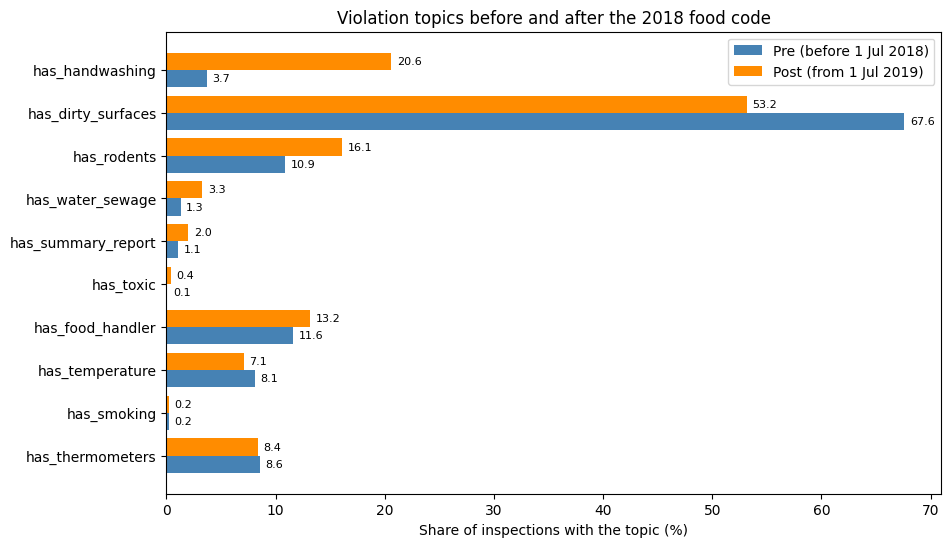

In [13]:
# bar chart of the H1c table: share of inspections with each topic, Pre vs Post
plot_data = h1c.iloc[::-1]   # reverse so the biggest change is at the top
y = np.arange(len(plot_data))
plt.figure(figsize=(10, 6))
plt.barh(y - 0.2, plot_data['Pre share'] * 100, height=0.4, color='steelblue', label='Pre (before 1 Jul 2018)')
plt.barh(y + 0.2, plot_data['Post share'] * 100, height=0.4, color='darkorange', label='Post (from 1 Jul 2019)')
for i in range(len(plot_data)):
    plt.text(plot_data['Pre share'].iloc[i] * 100 + 0.5, y[i] - 0.2, round(plot_data['Pre share'].iloc[i] * 100, 1), va='center', fontsize=8)
    plt.text(plot_data['Post share'].iloc[i] * 100 + 0.5, y[i] + 0.2, round(plot_data['Post share'].iloc[i] * 100, 1), va='center', fontsize=8)
plt.yticks(y, plot_data['Topic'])
plt.title('Violation topics before and after the 2018 food code')
plt.xlabel('Share of inspections with the topic (%)')
plt.legend()
plt.show()

The same H1c result as a bar chart: the topics are sorted by effect size, so the biggest changes (hand washing, dirty surfaces) are at the top, hand washing grows from 3.7% to 20.6% and dirty surfaces falls from 67.6% to 53.2%, while thermometers stays almost the same (8.6% vs 8.4%)

### H1 – Conclusion
The 2018 code changed **how inspections are recorded** more than **how often places fail**, the fail rate rose only a little (21.6% → 23.7%), but many results moved from Pass to Pass w/ Conditions (H1a, V = 0.21), inspections list slightly more violations, with many more "serious" ones (H1b), and the mix of violation topics changed, mainly hand washing and dirty surfaces (H1c), so H1 is supported: the data before and after 2018 is different, which is exactly why a model trained on old data may not work as well on new data

### H4 – Was the 90-day grace period different from the rest of the transition year?
**H0:** the shares of Pass / Pass w/ Conditions / Fail are the same in the grace period (1 July – 30 September 2018) and in the rest of the transition year
**H1:** they are different
**Assumptions:** two categorical variables (Period, Results), independent inspections, every expected count ≥ 5 
**Test:** chi-square test of independence

In [14]:
transition = final[final['Period'].isin(['Grace (90 days)', 'Late transition'])]
table_h4 = pd.crosstab(transition['Period'], transition['Results'])
pd.crosstab(transition['Period'], transition['Results'], normalize='index').round(3)

Results,Fail,Pass,Pass w/ Conditions
Period,,,
Grace (90 days),0.217,0.124,0.659
Late transition,0.209,0.239,0.551


Shares of each result in the two parts of the transition year: In the grace period only 12.4% of the inspections are a clean Pass and 65.9% are Pass w/ Conditions, compared to 23.9% and 55.1% in the rest of the transition year, the fail rate is almost the same (21.7% vs 20.9%)

In [15]:
chi2, p, dof, expected = stats.chi2_contingency(table_h4)
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p:.3e}, min expected = {expected.min():.0f}')
print(f"Cramer's V = {cramers_v(table_h4):.3f}")

Chi-square = 213.60, df = 2, p-value = 4.141e-47, min expected = 710
Cramer's V = 0.120


Result and interpretation: χ² = 213.60, df = 2, p ≈ 4.141e-47 (smallest expected count: 710), then we **reject H0**: the grace period is different from the rest of the transition year, Cramér's V = 0.120, a small effect, the difference is not in failing but in passing: during the grace period inspectors recorded the new violations without citing them, so many more places got Pass w/ Conditions instead of a clean Pass

### H5 – Does a business's previous result help predict its current result?
**H0:** failing the previous inspection and failing the current inspection are not related
**H1:** they are related  
**Assumptions:** we use only normal visits (no re-inspections), because a re-inspection right after a fail is usually a pass (see `04_History.ipynb`), and only businesses that have a previous visit, every expected count must be ≥ 5
**Test:** chi-square test of independence

In [16]:
normal = final[(final['Is_Reinspection'] == 0) & (final['First_Inspection'] == 0)]
table_h5 = pd.crosstab(normal['Prev_Fail'], normal['Fail'])
pd.crosstab(normal['Prev_Fail'], normal['Fail'], normalize='index').round(3)

Fail,0,1
Prev_Fail,,
0.0,0.749,0.251
1.0,0.666,0.334


Fail rate now, for businesses that passed (0) or failed (1) at their previous visit (normal visits only, no re-inspections and no first visits): 25.1% after a pass vs 33.4% after a fail

In [17]:
chi2, p, dof, expected = stats.chi2_contingency(table_h5)
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p:.3e}, min expected = {expected.min():.0f}')
print(f"Cramer's V = {cramers_v(table_h5):.3f}")

Chi-square = 23.25, df = 1, p-value = 1.425e-06, min expected = 161
Cramer's V = 0.017


Result and interpretation: χ² = 23.25, df = 1, p ≈ 1.425e-06 (smallest expected count:161), then we **reject H0**: a business that failed its last normal inspection is more likely to fail again (33.4% vs 25.1%), Cramér's V is only 0.017 because very few normal visits come right after a fail (most visits after a fail are re-inspections), but for those businesses the fail rate is about 8 percentage points higher, so the past helps to predict the future, which supports using the history columns in the model, even though the city says the data is "not intended to predict future findings"

### Risk level
The chi-square test for Risk × Fail is in `05_Risk_Location.ipynb` (χ² = 72.80, p ≈ 1.6 × 10⁻¹⁶, Spearman ρ = 0.013): the fail rate differs between risk levels, but the relationship is very weak, and part of it is explained by the much higher share of License inspections in Risk 3 (37.6% vs 11.2% in Risk 1)

## Summary of the results

| Hypothesis | Test | Statistic | p-value | Effect size | Decision |
|---|---|---|---|---|---|
| H1a – results distribution Pre vs Post | Chi-square | χ² = 4,772.35 (df = 2) | < 0.001 | Cramér's V = 0.206 (small–medium) | Reject H0 |
| H1b – number of violations Pre vs Post | Mann–Whitney U | U = 1,438,185,468 | ≈ 2.0 × 10⁻⁷⁵ | rank-biserial = −0.064 (very small) | Reject H0 |
| H1b – critical violations | Mann–Whitney U | U = 1,573,838,368 | ≈ 3.0 × 10⁻²⁹ | means 0.24 → 0.20 | Reject H0 (small change) |
| H1b – serious violations | Mann–Whitney U | U = 1,234,688,238 | < 0.001 | means 0.36 → 0.91 | Reject H0 |
| H1c – violation topics | 10 chi-square tests | largest: hand washing χ² = 8,037.7 | < 0.001 for 9 of 10 | V from 0.003 to 0.268 | Reject H0 for 9 topics (not thermometers) |
| H4 – grace period vs late transition | Chi-square | χ² = 213.60 (df = 2) | ≈ 4.1 × 10⁻⁴⁷ | Cramér's V = 0.120 (small) | Reject H0 |
| H5 – previous fail vs current fail (normal visits) | Chi-square | χ² = 23.25 (df = 1) | ≈ 1.4 × 10⁻⁶ | Cramér's V = 0.017 (fail rate 25.1% vs 33.4%) | Reject H0 |
| Risk level vs fail (05_Risk_Location) | Chi-square + Spearman | χ² = 72.80 (df = 2), ρ = 0.013 | ≈ 1.6 × 10⁻¹⁶ | very weak | Reject H0 (confounded by inspection type) |

H2 and H3 (model performance) are tested in Phase 2